# Aulas IA Preditiva Modulo1 Semana 10 Aula2

### Clean Data

In [ ]:
import unicodedata
import numpy as np
import pandas as pd

from script_functions import Visualizacao

class Analise:
    def __init__(self, dados):
        self.dados = dados

    def media_por(self, grupo, alvo="tempo_entrega_dias"):
        return self.dados.groupby(grupo)[alvo].agg(["count", "mean", "median"]).round(2)

class Graficos(Analise):
    
    # Distribuições
    def histograma(self, coluna, titulo, bins=30, limite=None):
        Visualizacao.histograma(self.dados, coluna, titulo, bins=bins, limite=limite)

    def boxplot(self, coluna, titulo, grupo=None, limite=None):
        Visualizacao.boxplot(self.dados, coluna, titulo, grupo=grupo, limite=limite)

    def comparar_histogramas(self, antes, depois, coluna, titulo_antes="Antes",
                             titulo_depois="Depois", bins=30, limite=None):
        Visualizacao.comparar_histogramas(antes, depois, coluna, titulo_antes, titulo_depois, bins, limite)

    def comparar_boxplots(self, antes, depois, coluna, titulo_antes="Antes",
                          titulo_depois="Depois", grupo=None, limite=None):
        Visualizacao.comparar_boxplots(antes, depois, coluna, titulo_antes, titulo_depois, grupo, limite)

    # Categorias e totais
    def barras_serie(self, serie, titulo, fmt="%.0f", horizontal=False, rotulo_valor="Quantidade"):
        Visualizacao.barras_serie(serie, titulo, fmt=fmt, horizontal=horizontal, rotulo_valor=rotulo_valor)

    def barras(self, categoria, valor, titulo, horizontal=False):
        Visualizacao.barras(self.dados, categoria, valor, titulo, horizontal=horizontal)

    def pizza(self, rotulo, valor, titulo=None):
        Visualizacao.pizza(self.dados, rotulo, valor, titulo)

    def mapa_calor(self, tabela, titulo, fmt="d"):
        Visualizacao.mapa_calor(tabela, titulo, fmt=fmt)

    def comparar_barras(self, antes, depois, titulo, rotulo_antes="Antes",
                        rotulo_depois="Depois", fmt="%.0f", horizontal=False):
        Visualizacao.comparar_barras(antes, depois, titulo, rotulo_antes, rotulo_depois, fmt, horizontal)

    # Relação entre duas colunas e linhas
    def dispersao(self, x, y, titulo, hue=None):
        Visualizacao.dispersao(self.dados, x, y, titulo, hue=hue)

    def linhas(self, x, y, titulo=None, marcador="o"):
        Visualizacao.linhas(self.dados, x, y, titulo, marcador=marcador)

    # Ausentes (usa os dados da instância)
    def mapa_ausentes(self, titulo, max_linhas=400):
        Visualizacao.mapa_ausentes(self.dados, titulo, max_linhas=max_linhas)

    def grafico_percentual_ausentes(self, titulo):
        Visualizacao.percentual_ausentes(self.dados, titulo)


In [2]:
class Limpeza(Graficos):
    def __init__(self, dados):
        self.dados = dados.copy()
        self.registro = []

    def registrar(self, passo, antes, depois):
        self.registro.append({"passo": passo, "antes": antes, "depois": depois})

    def relatorio(self):
        return pd.DataFrame(self.registro)

    def get_dados(self):
        return self.dados

In [3]:
pd.set_option("display.width", 120)
df_sujo = pd.read_csv("entregas_sujas.csv")
print(df_sujo.shape)

limpeza = Limpeza(df_sujo)

limpeza.get_dados().head(5)

(3000, 22)


,id_pedido,id_cliente,data_pedido,data_envio,data_entrega,estado,regiao,cidade,distancia_km,categoria_produto,...,quantidade_itens,valor_pedido,tipo_frete,transportadora,custo_frete,clima_envio,dia_semana_envio,fim_semana,dias_para_envio,tempo_entrega_dias
0,PED100147,CLI3792,2026-05-01,2026-05-04,2026-05-06,SP,Sudeste,São Paulo,48.8,Casa e cozinha,...,1.0,235.31,Padrão,CargaSul,20.88,Ensolarado,segunda,0,3,20.0
1,PED100936,CLI3680,2025-02-25,2025-02-27,2025-03-05,BA,Nordeste,Salvador,2254.0,Casa e cozinha,...,1.0,252.05,Padrão,Rápido Log,61.47,Ensolarado,quinta,0,2,6.0
2,PED100012,CLI2267,2026-01-05,2026-01-06,2026-01-15,PA,Norte,Belém,NaN,eletrônicos,...,1.0,375.63,Padrão,Log Nacional,57.80,Chuva,terça,0,1,9.0
3,PED102451,CLI1825,2025-01-31,2025-02-02,2025-02-10,PE,Nordeste,Recife,2495.3,Livros,...,1.0,62.45,Padrão,Rápido Log,78.98,Ensolarado,domingo,1,2,8.0
4,PED101056,CLI3045,2025-09-18,2025-09-20,2025-09-25,MG,Sudeste,Belo Horizonte,636.8,Roupas,...,2.0,195.68,Padrão,Rápido Log,26.53,Tempestade,sábado,1,2,5.0


### Tratamento de valores ausentes

Empty DataFrame
Columns: []
Index: []


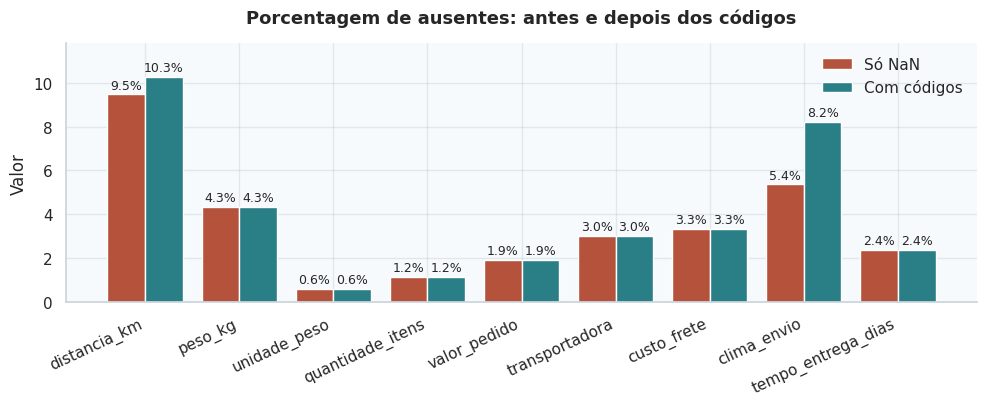

In [4]:
class TratadorAusentes(Limpeza):
    TOKENS = ["não informado", "--", -999]

    def percentual_ausentes(self):
        return (self.dados.isna().mean() * 100).round(1).sort_values(ascending=False)

    def converter_tokens(self):
        antes = int(self.dados.isna().sum().sum()) 
        # tratando os ausentes
        self.dados = self.dados.replace(self.TOKENS, np.nan)
        self.registrar("códigos de ausência -> NaN", antes, int(self.dados.isna().sum().sum()))

    def percentual_por_grupo(self, coluna, grupo):
        return self.dados.groupby(grupo)[coluna].apply(lambda s: s.isna().mean() * 100).round(1)

limpeza_ausente = TratadorAusentes(limpeza.dados)

''' # self.dados.isna().sum()
id_pedido	10
id_cliente	5
data_pedido	5
data_envio	0
data_entrega 10	

self.dados.isna().sum().sum()
30
'''

ausentes_antes = df_sujo.isna().mean().mul(100)
limpeza_ausente.converter_tokens() # ["não informado", "--", -999] -> NaN
print(limpeza.relatorio())
ausentes_depois = limpeza_ausente.dados.isna().mean().mul(100)
colunas = ausentes_depois[ausentes_depois > 0].index

limpeza_ausente.comparar_barras(ausentes_antes[colunas], ausentes_depois[colunas],\
                         "Porcentagem de ausentes: antes e depois dos códigos",\
                         "Só NaN", "Com códigos", fmt="%.1f%%")
# Saída:
#                         passo  antes  depois
# 0  códigos de ausência -> NaN    948    1057



In [5]:
print(limpeza_ausente.percentual_ausentes())

distancia_km          10.3
clima_envio            8.2
peso_kg                4.3
custo_frete            3.3
transportadora         3.0
tempo_entrega_dias     2.4
valor_pedido           1.9
quantidade_itens       1.2
unidade_peso           0.6
data_entrega           0.0
id_cliente             0.0
id_pedido              0.0
data_envio             0.0
data_pedido            0.0
estado                 0.0
cidade                 0.0
categoria_produto      0.0
regiao                 0.0
tipo_frete             0.0
dia_semana_envio       0.0
fim_semana             0.0
dias_para_envio        0.0
dtype: float64


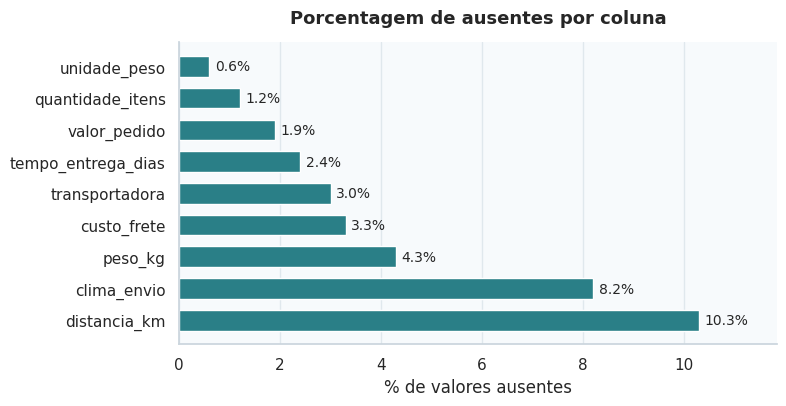

In [6]:
limpeza_ausente.grafico_percentual_ausentes("Porcentagem de ausentes por coluna")

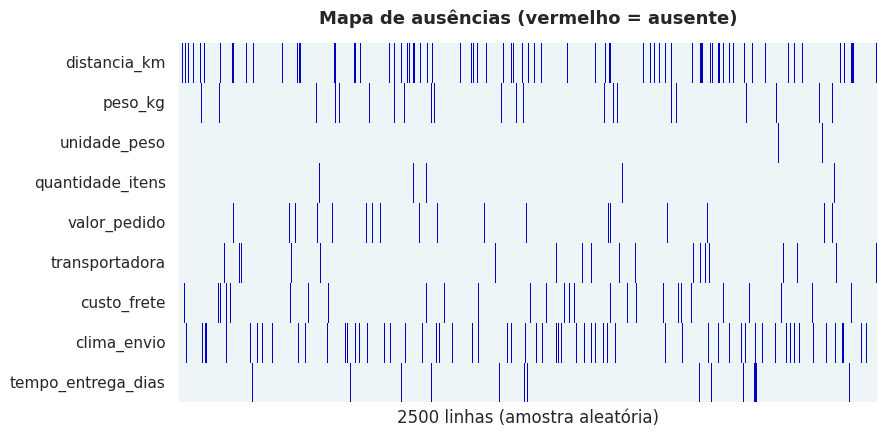

In [7]:
limpeza_ausente.mapa_ausentes("Mapa de ausências (vermelho = ausente)", max_linhas=2500)

### Tratamento de normalizar texto

In [32]:
class TratadorTexto(TratadorAusentes):
    @staticmethod
    def chave(texto):
        sem_acento = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode()
        return sem_acento.lower().replace(" ", "")

    def padronizar_categorias(self, coluna, valores):
        mapa = {self.chave(v): v for v in valores}
        antes = self.dados[coluna].nunique()
        self.dados[coluna] = self.dados[coluna].map(
            lambda t: mapa.get(self.chave(t), t) if isinstance(t, str) else t)
        self.registrar(f"{coluna}: categorias padronizadas", antes, self.dados[coluna].nunique())

limpeza_texto = TratadorTexto(limpeza_ausente.dados)

VALORES = {
    "estado": ["AM", "BA", "CE", "DF", "GO", "MG", "PA", "PE", "PR", "RJ", "RS", "SC", "SP"],
    "regiao": ["Centro-Oeste", "Nordeste", "Norte", "Sudeste", "Sul"],
    "tipo_frete": ["Econômico", "Expresso", "Padrão"],
    "transportadora": ["CargaSul", "Entrega Ágil", "Log Nacional", "Rápido Log"],
    "categoria_produto": ["Brinquedos", "Casa e cozinha", "Eletrônicos", "Ferramentas", "Livros", "Roupas"],
}
for coluna, valores in VALORES.items():
    limpeza_texto.padronizar_categorias(coluna, valores)

print(limpeza_texto.relatorio().tail(5))



                                        passo  antes  depois
0             estado: categorias padronizadas     52      13
1             regiao: categorias padronizadas     15       5
2         tipo_frete: categorias padronizadas     12       3
3     transportadora: categorias padronizadas     15       4
4  categoria_produto: categorias padronizadas     12       6


regiao
Sudeste         1251
Sul              589
Nordeste         585
Norte            266
Centro-Oeste     173
sudeste           33
SUDESTE           23
SUL               17
sul               17
nordeste          16
NORDESTE          13
norte              9
NORTE              4
CENTRO-OESTE       2
centro-oeste       2
Name: count, dtype: int64
--------
regiao
Sudeste         1307
Sul              623
Nordeste         614
Norte            279
Centro-Oeste     177
Name: count, dtype: int64


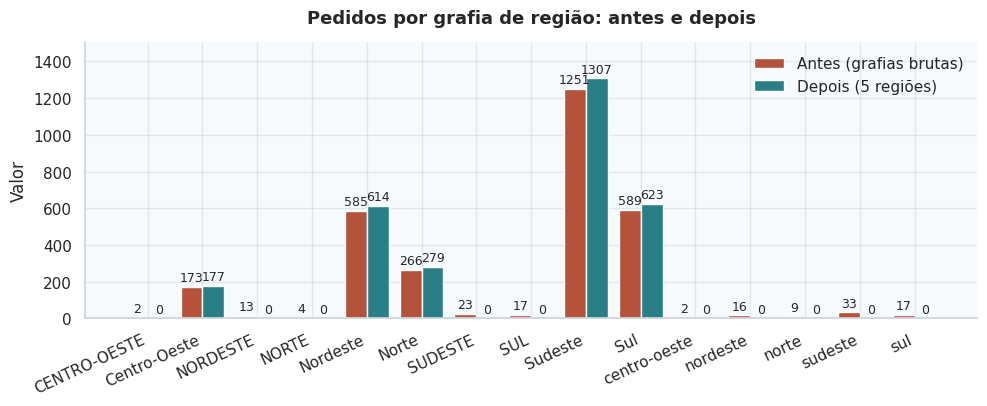

In [9]:
regiao_antes = df_sujo["regiao"].value_counts()
print(regiao_antes)
print("--------")
regiao_depois = limpeza_texto.dados["regiao"].value_counts()
print(regiao_depois)
limpeza_texto.comparar_barras(regiao_antes, regiao_depois,\
 "Pedidos por grafia de região: antes e depois",\
 "Antes (grafias brutas)", "Depois (5 regiões)", fmt="%.0f")

### Tratamento de valores monetarios (tipo)

categoria_produto
Brinquedos        411
Casa e cozinha    490
Eletrônicos       600
Ferramentas       409
Livros            233
Name: valor_pedido, dtype: int64
---------
count     2942.00
mean       587.82
std       1680.52
min         16.50
25%        132.31
50%        249.51
75%        567.53
max      65467.00
Name: valor_pedido, dtype: float64
---------
categoria_produto
Brinquedos        419
Casa e cozinha    520
Eletrônicos       627
Ferramentas       427
Livros            252
Name: valor_pedido, dtype: int64 12


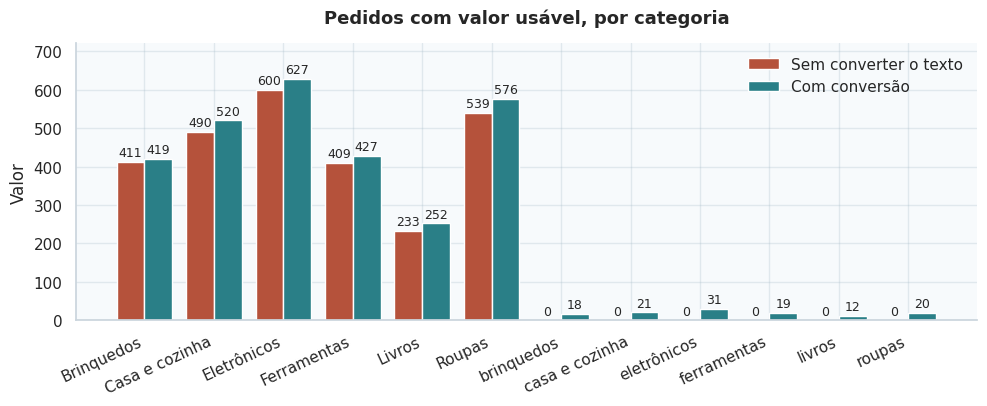

In [10]:
class TratadorTipos(TratadorTexto):
    @staticmethod
    def _moeda(valor):
        if isinstance(valor, str):
            texto = valor.replace("R$", "").strip()
            if "," in texto:  # formato brasileiro: 1.250,50 (ponto separa milhar, vírgula é decimal) -> 1250.50
                texto = texto.replace(".", "").replace(",", ".")
            return float(texto)  # sem vírgula: já está em formato 1250.50
        return valor

    def converter_moeda(self, coluna):
        textos = int(self.dados[coluna].map(lambda v: isinstance(v, str)).sum())
        self.dados[coluna] = pd.to_numeric(self.dados[coluna].map(self._moeda))
        self.registrar(f"{coluna}: texto -> número", textos, 0)

    def converter_datas(self, colunas):
        for coluna in colunas:
            textos = int(self.dados[coluna].map(lambda v: isinstance(v, str)).sum())
            self.dados[coluna] = pd.to_datetime(self.dados[coluna], format="mixed", dayfirst=True)
            self.registrar(f"{coluna}: texto -> data", textos, 0)
            

com_valor_antes = (pd.to_numeric(limpeza_texto.dados["valor_pedido"], errors="coerce")
                   .groupby(limpeza_texto.dados["categoria_produto"]).count())

print(com_valor_antes[:5])

limpeza_tipo = TratadorTipos(limpeza_texto.dados)
limpeza_tipo.converter_moeda("valor_pedido")
print("---------")
print(limpeza_tipo.dados["valor_pedido"].describe().round(2))
com_valor_depois = limpeza_tipo.dados["valor_pedido"].groupby(limpeza.dados["categoria_produto"]).count()
print("---------")
print(com_valor_depois[:5], len(com_valor_depois))

limpeza_tipo.comparar_barras(com_valor_antes, com_valor_depois, "Pedidos com valor usável, por categoria",\
    "Sem converter o texto", "Com conversão", fmt="%.0f")



data_pedido
2025Q1    455
2025Q2    454
2025Q3    485
2025Q4    449
2026Q1    416
2026Q2    456
Freq: Q-DEC, Name: count, dtype: int64
  data_pedido data_envio data_entrega
0  2026-05-01 2026-05-04   2026-05-06
1  2025-02-25 2025-02-27   2025-03-05
2  2026-01-05 2026-01-06   2026-01-15
-------
data_pedido
2025Q1    500
2025Q2    496
2025Q3    537
2025Q4    501
2026Q1    464
2026Q2    502
Freq: Q-DEC, Name: count, dtype: int64


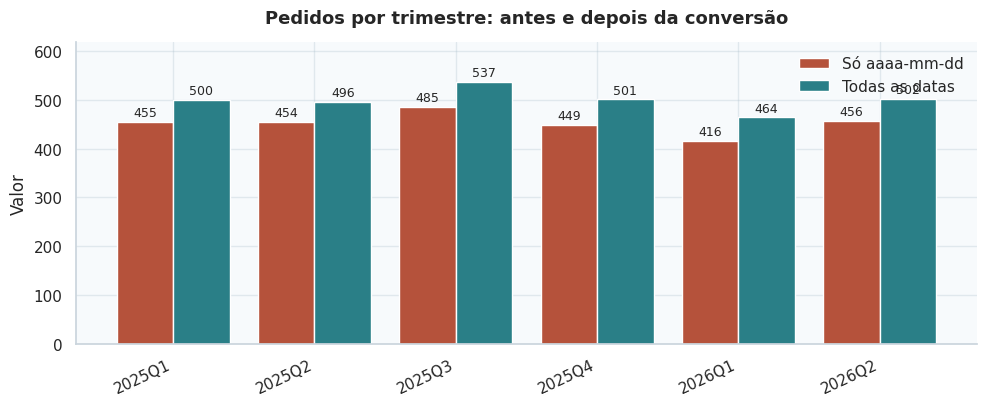

In [11]:
por_trimestre_antes = (pd.to_datetime(limpeza_tipo.dados["data_pedido"], format="%Y-%m-%d", errors="coerce")\
                       .dt.to_period("Q").value_counts().sort_index())

print(por_trimestre_antes)

limpeza_tipo.converter_datas(["data_pedido", "data_envio", "data_entrega"])
print(limpeza_tipo.dados[["data_pedido", "data_envio", "data_entrega"]].head(3))

print("-------")
por_trimestre_depois = limpeza_tipo.dados["data_pedido"].dt.to_period("Q").value_counts().sort_index()
print(por_trimestre_depois)
limpeza_tipo.comparar_barras(por_trimestre_antes, por_trimestre_depois, \
                        "Pedidos por trimestre: antes e depois da conversão",\
                         "Só aaaa-mm-dd", "Todas as datas", fmt="%.0f")


### Tratamento de Tipo (g - kg)

categoria_produto
Brinquedos        235.090718
Casa e cozinha    371.972549
Eletrônicos       252.266985
Ferramentas       701.014791
Livros             63.092724
Roupas             82.678603
Name: peso_kg, dtype: float64
count    2870.00
mean        5.36
std        28.87
min         0.34
25%         1.68
50%         3.31
75%         6.38
max      1530.00
Name: peso_kg, dtype: float64
Pesos sem unidade para revisar: 18


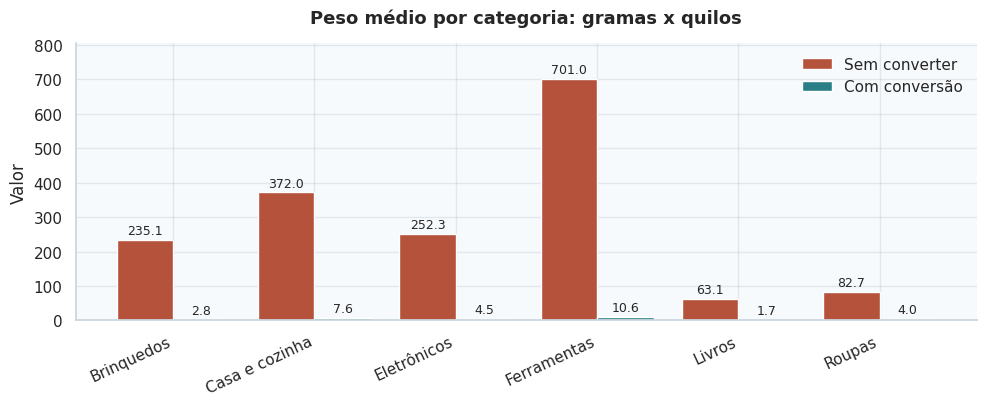

In [27]:
class TratadorUnidades(TratadorTipos):

    def padronizar_peso_kg(self):
        gramas = self.dados["unidade_peso"] == "g"
        self.dados.loc[gramas, "peso_kg"] = self.dados.loc[gramas, "peso_kg"] / 1000
        self.dados.loc[gramas, "unidade_peso"] = "kg"
        self.dados["revisar_peso"] = self.dados["unidade_peso"].isna()
        self.registrar("peso em gramas -> kg", int(gramas.sum()), 0)

limpeza_unidades = TratadorUnidades(limpeza_tipo.dados)
peso_antes = limpeza_unidades.dados.groupby("categoria_produto")["peso_kg"].mean()
print(peso_antes)
limpeza_unidades.padronizar_peso_kg()
print(limpeza_unidades.dados["peso_kg"].describe().round(2))
print("Pesos sem unidade para revisar:", limpeza_unidades.dados["revisar_peso"].sum())
peso_depois = limpeza_unidades.dados.groupby("categoria_produto")["peso_kg"].mean()
limpeza.comparar_barras(peso_antes, peso_depois, "Peso médio por categoria: gramas x quilos", "Sem converter", "Com conversão", fmt="%.1f")


### Tratamento de duplicados

                         passo  antes  depois
0  duplicados exatos removidos   3000    2850


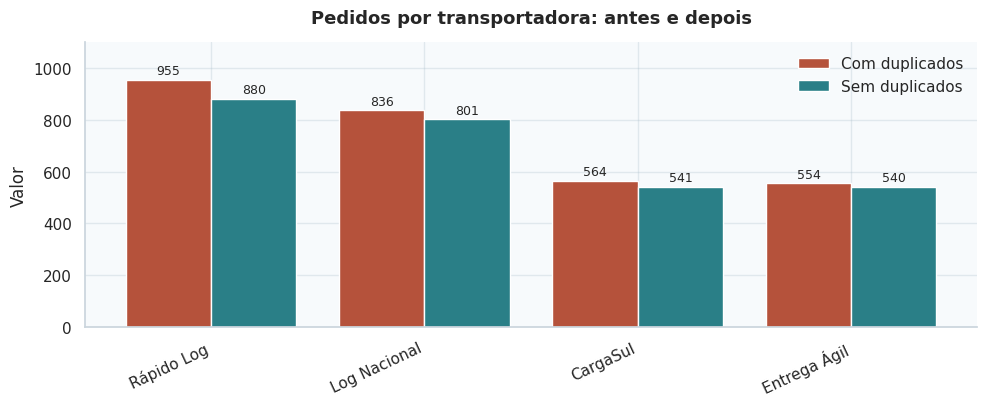

In [47]:
class TratadorDuplicados(TratadorUnidades):

    def remover_exatos(self):
        antes = len(self.dados)
        self.dados = self.dados.drop_duplicates() # remover os duplicado
        self.registrar("duplicados exatos removidos", antes, len(self.dados))

    def conflitos(self, chave="id_pedido"):
        repetidos = self.dados.duplicated(subset=chave, keep=False) #[true false ....] keep=False foca na variavel e True exclue a variavel
        return self.dados[repetidos].sort_values(chave)

    def remover_por_chave(self, chave="id_pedido"):
        antes = len(self.dados)
        self.dados = self.dados.drop_duplicates(subset=chave, keep="first")
        self.registrar(f"duplicados por {chave} (mantém o primeiro)", antes, len(self.dados))


limpeza_duplicados = TratadorDuplicados(limpeza_tipo.dados)

antes_dup = limpeza_duplicados.dados["transportadora"].value_counts()
limpeza_duplicados.remover_exatos()
print(limpeza_duplicados.relatorio().tail(1))

limpeza_duplicados.comparar_barras(antes_dup, limpeza_duplicados.dados["transportadora"].value_counts(),\
        "Pedidos por transportadora: antes e depois", "Com duplicados", "Sem duplicados")



      id_pedido  custo_frete transportadora
2133  PED100007        69.83       CargaSul
1742  PED100007        83.80       CargaSul
53    PED100027        11.49     Rápido Log
950   PED100027        13.79     Rápido Log
1678  PED100126        22.95   Entrega Ágil
1813  PED100126        27.54   Entrega Ágil
1570  PED100127        63.07   Log Nacional
                                          passo  antes  depois
1  duplicados por id_pedido (mantém o primeiro)   2850    2820


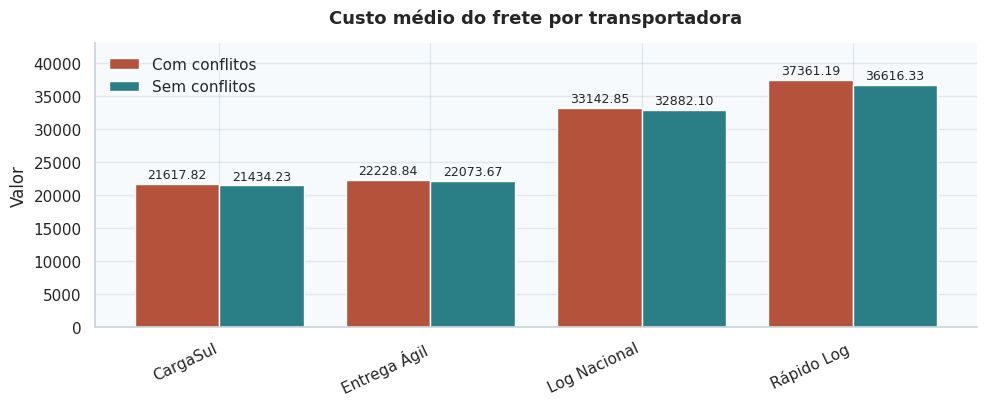

In [48]:
conflitos = limpeza_duplicados.conflitos("id_pedido")
print(conflitos[["id_pedido", "custo_frete", "transportadora"]].head(7))
custo_antes = limpeza_duplicados.dados.groupby("transportadora")["custo_frete"].sum()

limpeza_duplicados.remover_por_chave("id_pedido")
print(limpeza_duplicados.relatorio().tail(1))

custo_depois = limpeza_duplicados.dados.groupby("transportadora")["custo_frete"].sum()
limpeza_duplicados.comparar_barras(custo_antes, custo_depois, "Custo médio do frete por transportadora",\
    "Com conflitos", "Sem conflitos", fmt="%.2f")


### Tratamento de inconsitencias

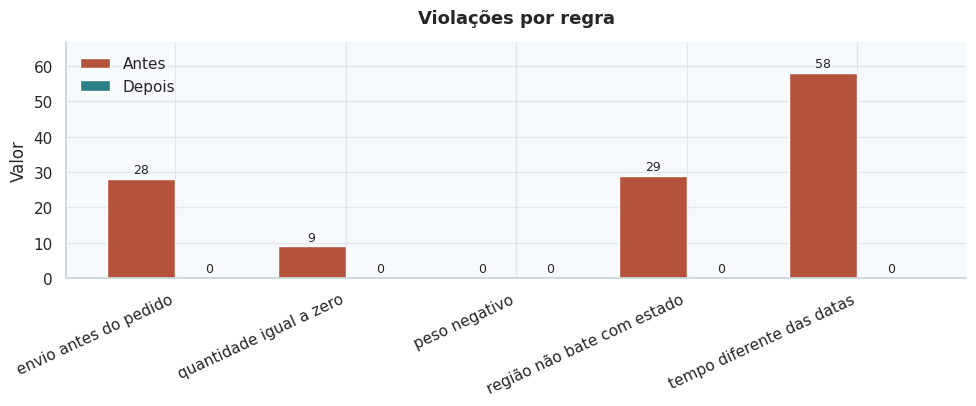

                            antes  depois
envio antes do pedido          28       0
quantidade igual a zero         9       0
peso negativo                   0       0
região não bate com estado     29       0
tempo diferente das datas      58       0


In [51]:
class TratadorConsistencia(TratadorDuplicados):
    REGIAO_DE_UF = {
        "AM": "Norte", "PA": "Norte", "BA": "Nordeste", "PE": "Nordeste", "CE": "Nordeste",
        "SP": "Sudeste", "RJ": "Sudeste", "MG": "Sudeste", "PR": "Sul", "SC": "Sul",
        "RS": "Sul", "GO": "Centro-Oeste", "DF": "Centro-Oeste",
    }

    def diagnosticar(self):
        d = self.dados
        dias = (d["data_entrega"] - d["data_envio"]).dt.days
        return pd.Series({
            "envio antes do pedido": int((d["data_envio"] < d["data_pedido"]).sum()),
            "quantidade igual a zero": int((d["quantidade_itens"] == 0).sum()),
            "peso negativo": int((d["peso_kg"] <= 0.000).sum()),
            "região não bate com estado": int((d["estado"].map(self.REGIAO_DE_UF) != d["regiao"]).sum()),
            "tempo diferente das datas": int(((d["tempo_entrega_dias"] - dias).abs() > 0).sum()),
        })

    def corrigir(self):
        d = self.dados
        antes = int(self.diagnosticar().sum())
        d.loc[d["data_envio"] < d["data_pedido"], "data_envio"] = pd.NaT # operações especificas
        d.loc[d["quantidade_itens"] == 0, "quantidade_itens"] = np.nan
        d.loc[d["peso_kg"] < 0, "peso_kg"] = np.nan
        d["regiao"] = d["estado"].map(self.REGIAO_DE_UF)
        dias = (d["data_entrega"] - d["data_envio"]).dt.days
        erro = (d["tempo_entrega_dias"] - dias).abs() > 0
        d.loc[erro, "tempo_entrega_dias"] = dias[erro]
        d.loc[d["data_envio"].isna(), "tempo_entrega_dias"] = np.nan
        self.registrar("inconsistências corrigidas", antes, int(self.diagnosticar().sum()))

limpeza_inconsistencia = TratadorConsistencia(limpeza_duplicados.dados)

antes_corr = limpeza_inconsistencia.diagnosticar()
limpeza_inconsistencia.corrigir()
depois_corr = limpeza_inconsistencia.diagnosticar()

limpeza_inconsistencia.comparar_barras(antes_corr, depois_corr, "Violações por regra", "Antes", "Depois")

print(pd.DataFrame({"antes": antes_corr, "depois": depois_corr}))



### Tratamento de ausentes rotulados

In [54]:
class ImputadorAusentes(TratadorConsistencia):
    
    def comparar_estrategias(self, coluna, grupo):
        base = self.dados[coluna]
        return pd.DataFrame({
            "original": base,
            "media": base.fillna(base.mean()),
            "mediana": base.fillna(base.median()),
            "mediana_grupo": base.fillna(self.dados.groupby(grupo)[coluna].transform("median")),
        })

    def indicar_ausente(self, coluna):
        self.dados[f"{coluna}_ausente"] = self.dados[coluna].isna().astype(int)

    def preencher_mediana_grupo(self, coluna, grupo):
        antes = int(self.dados[coluna].isna().sum())
        medianas = self.dados.groupby(grupo)[coluna].transform("median")
        self.dados[coluna] = self.dados[coluna].fillna(medianas)
        self.registrar(f"{coluna}: NaN -> mediana de {grupo}", antes, int(self.dados[coluna].isna().sum()))

    def preencher_constante(self, coluna, valor):
        antes = int(self.dados[coluna].isna().sum())
        self.dados[coluna] = self.dados[coluna].fillna(valor)
        self.registrar(f"{coluna}: NaN -> {valor}", antes, int(self.dados[coluna].isna().sum()))

    def remover_sem_alvo(self):
        antes = len(self.dados)
        self.dados = self.dados.dropna(subset=["tempo_entrega_dias"])
        self.registrar("linhas sem alvo removidas", antes, len(self.dados))

limpeza_ausentes_rotulados = ImputadorAusentes(limpeza_inconsistencia.dados)
comparacao = limpeza_ausentes_rotulados.comparar_estrategias("peso_kg", "categoria_produto")
print(comparacao.describe().round(2))



       original     media   mediana  mediana_grupo
count   2698.00   2820.00   2820.00        2820.00
mean     281.89    281.89    269.85         269.91
std     1672.35   1635.76   1636.74        1636.73
min        0.34      0.34      0.34           0.34
25%        1.74      1.80      1.80           1.76
50%        3.57      3.79      3.57           3.62
75%        7.19      8.00      6.95           7.17
max    27640.00  27640.00  27640.00       27640.00


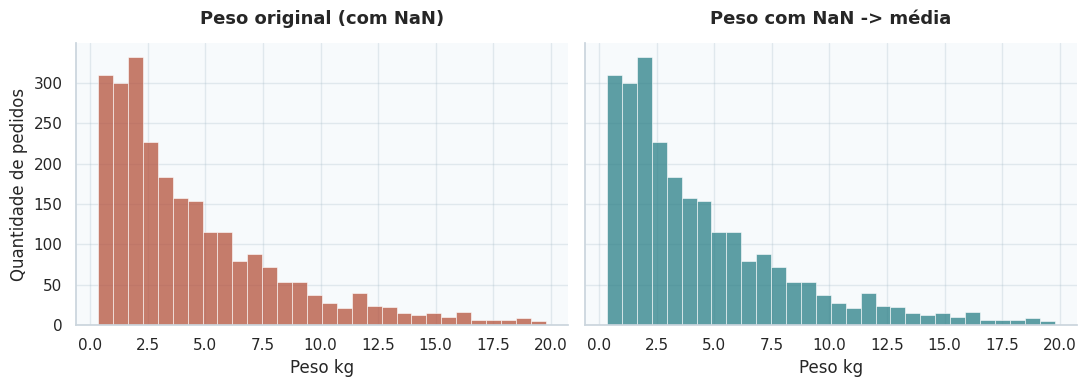

In [55]:
antes_media = pd.DataFrame({"peso_kg": comparacao["original"]}).query("peso_kg.between(0, 20)")
depois_media = pd.DataFrame({"peso_kg": comparacao["media"]}).query("peso_kg.between(0, 20)")
limpeza.comparar_histogramas(antes_media, depois_media, "peso_kg",\
        "Peso original (com NaN)", "Peso com NaN -> média")


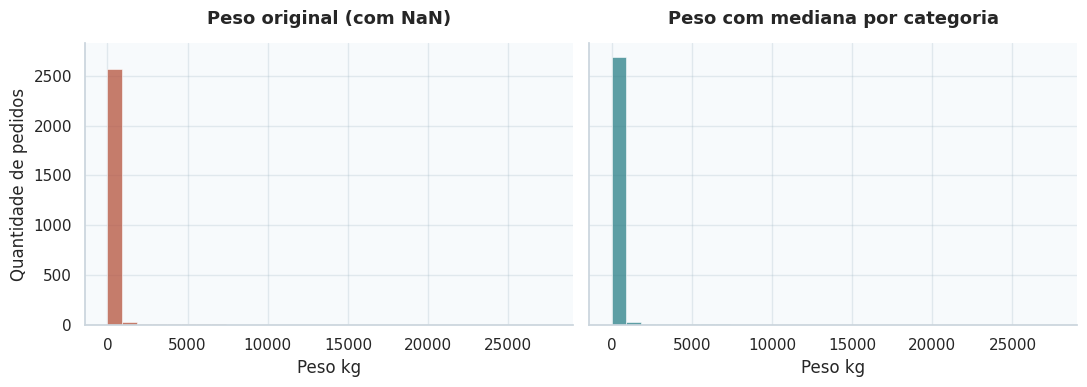

In [56]:
antes_peso = pd.DataFrame({"peso_kg": comparacao["original"]})
depois_peso = pd.DataFrame({"peso_kg": comparacao["mediana_grupo"]})
limpeza.comparar_histogramas(antes_peso, depois_peso, "peso_kg",\
    "Peso original (com NaN)", "Peso com mediana por categoria")


                                    passo  antes  depois
0  distancia_km: NaN -> mediana de estado    297       0


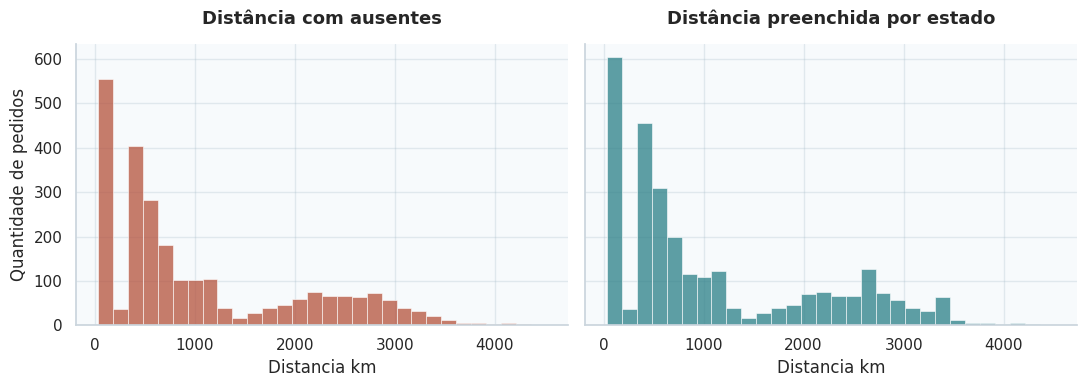

In [57]:
distancia_antes = limpeza_ausentes_rotulados.dados[["distancia_km"]].copy()
limpeza_ausentes_rotulados.indicar_ausente("distancia_km")
limpeza_ausentes_rotulados.preencher_mediana_grupo("distancia_km", "estado")
print(limpeza_ausentes_rotulados.relatorio().tail(1))
limpeza_ausentes_rotulados.comparar_histogramas(distancia_antes, limpeza_ausentes_rotulados.dados[["distancia_km"]], "distancia_km",
                             "Distância com ausentes", "Distância preenchida por estado")


In [59]:
limpeza_ausentes_rotulados.preencher_mediana_grupo("peso_kg", "categoria_produto")
limpeza_ausentes_rotulados.preencher_mediana_grupo("custo_frete", "tipo_frete")
limpeza_ausentes_rotulados.preencher_mediana_grupo("valor_pedido", "categoria_produto")
limpeza_ausentes_rotulados.preencher_mediana_grupo("quantidade_itens", "categoria_produto")
limpeza_ausentes_rotulados.preencher_constante("clima_envio", "Desconhecido")
limpeza_ausentes_rotulados.preencher_constante("transportadora", "Desconhecida")

print(limpeza_ausentes_rotulados.dados.isna().sum()[lambda s: s > 0])


data_envio            28
unidade_peso          18
tempo_entrega_dias    93
dtype: int64


In [60]:
limpeza_ausentes_rotulados.remover_sem_alvo()
print(limpeza_ausentes_rotulados.relatorio())


                                                passo  antes  depois
0              distancia_km: NaN -> mediana de estado    297       0
1        peso_kg: NaN -> mediana de categoria_produto    122       0
2           custo_frete: NaN -> mediana de tipo_frete     95       0
3   valor_pedido: NaN -> mediana de categoria_produto     54       0
4   quantidade_itens: NaN -> mediana de categoria_...     42       0
5                    clima_envio: NaN -> Desconhecido    234       0
6                 transportadora: NaN -> Desconhecida     86       0
7        peso_kg: NaN -> mediana de categoria_produto      0       0
8           custo_frete: NaN -> mediana de tipo_frete      0       0
9   valor_pedido: NaN -> mediana de categoria_produto      0       0
10  quantidade_itens: NaN -> mediana de categoria_...      0       0
11                   clima_envio: NaN -> Desconhecido      0       0
12                transportadora: NaN -> Desconhecida      0       0
13                          linhas

### Tratamento de Outliers, valores extremos

(-4.5, 15.5)
Candidatos pelo IQR: 7


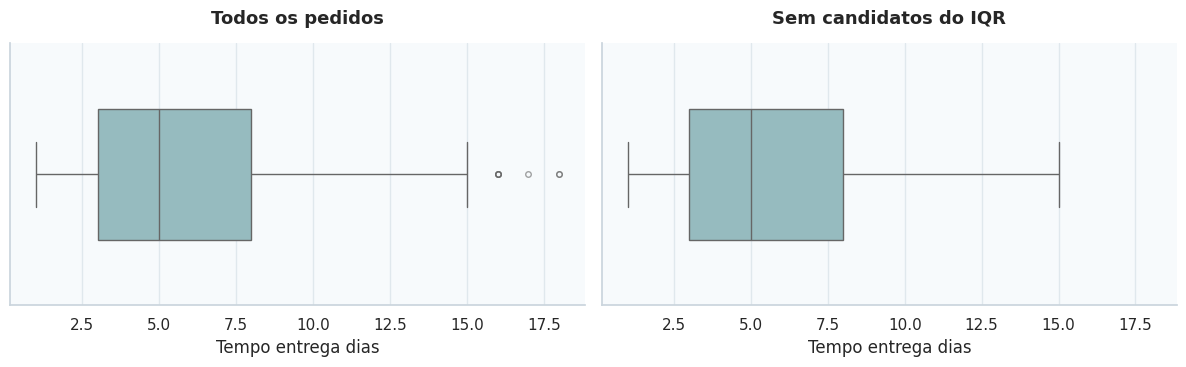

In [77]:
class TratadorOutliers(ImputadorAusentes):
    def limites_iqr(self, coluna, k=1.5):
        q1, q3 = self.dados[coluna].quantile([0.25, 0.75])
        iqr = q3 - q1
        return q1 - k * iqr, q3 + k * iqr

    def mascara_iqr(self, coluna, k=1.5):
        inferior, superior = self.limites_iqr(coluna, k)
        return (self.dados[coluna] < inferior) | (self.dados[coluna] > superior)

    def sem_outliers(self, coluna, k=1.5):
        return self.dados[~self.mascara_iqr(coluna, k)]

    def remover_fora_dominio(self, coluna, minimo, maximo):
        antes = len(self.dados)
        dentro = self.dados[coluna].between(minimo, maximo) | self.dados[coluna].isna()
        self.dados = self.dados[dentro]
        self.registrar(f"{coluna} fora de [{minimo}, {maximo}]", antes, len(self.dados))

    def remover_valor_suspeito(self, fator=20):
        unitario = self.dados["valor_pedido"] / self.dados["quantidade_itens"]
        mediana = unitario.groupby(self.dados["categoria_produto"]).transform("median")
        suspeito = unitario > fator * mediana
        antes = len(self.dados)
        self.dados = self.dados[~suspeito]
        self.registrar(f"valor unitário > {fator} x mediana da categoria", antes, len(self.dados))

limpeza_outliers = TratadorOutliers(limpeza_ausentes_rotulados.dados)

print(limpeza_outliers.limites_iqr("tempo_entrega_dias"))
print("Candidatos pelo IQR:", int(limpeza_outliers.mascara_iqr("tempo_entrega_dias").sum()))

sem_iqr = limpeza_outliers.sem_outliers("tempo_entrega_dias")
limpeza_outliers.comparar_boxplots(limpeza_outliers.dados, sem_iqr, "tempo_entrega_dias", "Todos os pedidos", "Sem candidatos do IQR")



                                        passo  antes  depois
0  valor unitário > 20 x mediana da categoria   2727    2720
1                     peso_kg fora de [0, 50]   2720    2584


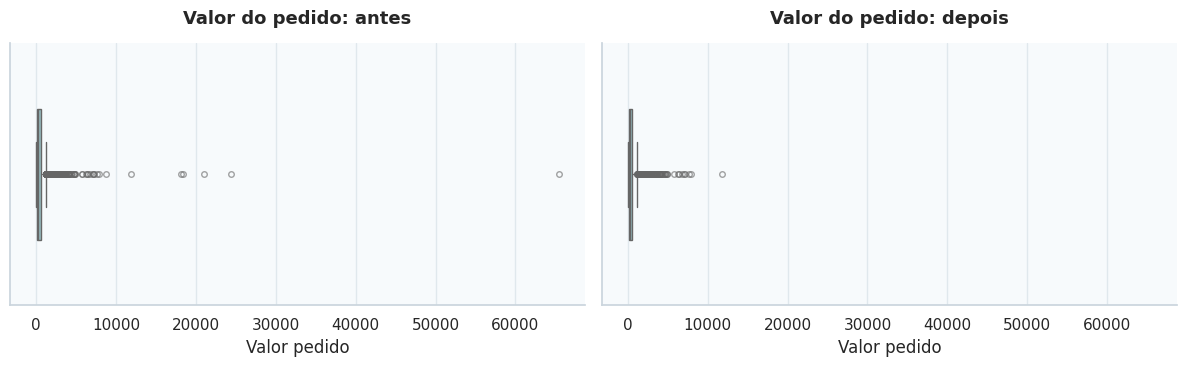

In [78]:
valor_antes = limpeza_outliers.dados[["valor_pedido"]].copy()
valor_antes_peso = limpeza_outliers.dados[["peso_kg"]].copy()
limpeza_outliers.remover_valor_suspeito()
limpeza_outliers.remover_fora_dominio("peso_kg", 0, 50)
print(limpeza_outliers.relatorio().tail(2))
limpeza_outliers.comparar_boxplots(valor_antes, limpeza_outliers.dados[["valor_pedido"]], "valor_pedido",\
    "Valor do pedido: antes", "Valor do pedido: depois")


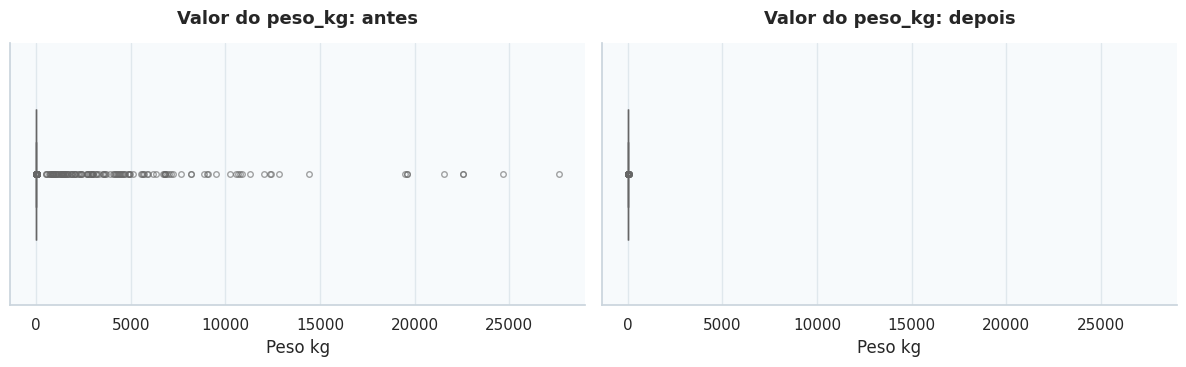

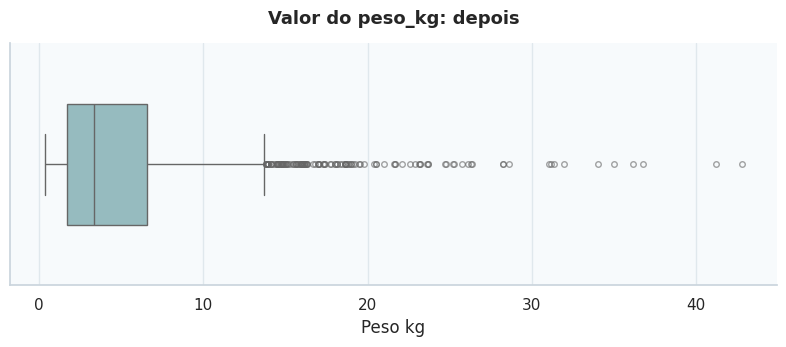

In [79]:

limpeza_outliers.comparar_boxplots(valor_antes_peso, limpeza_outliers.dados[["peso_kg"]], "peso_kg",\
    "Valor do peso_kg: antes", "Valor do peso_kg: depois")

# (self, coluna, titulo, grupo=None, limite=None):
limpeza_outliers.boxplot("peso_kg", "Valor do peso_kg: depois")

         atual  capping
count  2584.00  2584.00
mean      5.41     5.40
std       3.48     3.47
min       1.00     1.00
25%       3.00     3.00
50%       5.00     5.00
75%       8.00     8.00
max      18.00    15.50


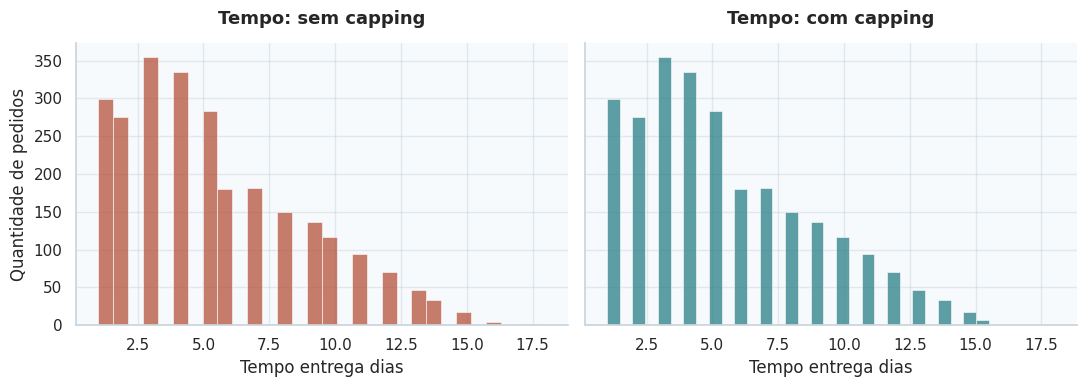

In [80]:
limite = limpeza_outliers.limites_iqr("tempo_entrega_dias")[1]
com_limite = limpeza_outliers.dados["tempo_entrega_dias"].clip(upper=limite)
print(pd.DataFrame({"atual": limpeza_outliers.dados["tempo_entrega_dias"].describe(),
                    "capping": com_limite.describe()}).round(2))
limpeza_outliers.comparar_histogramas(limpeza_outliers.dados, com_limite.to_frame(), "tempo_entrega_dias",
                             "Tempo: sem capping", "Tempo: com capping")
# Saída:
#          atual  capping
# count  2719.00  2719.00
# mean      5.42     5.41
# std       3.48     3.47
# min       1.00     1.00
# 25%       3.00     3.00
# 50%       5.00     5.00
# 75%       8.00     8.00
# max      18.00    15.50


### Dividindo em treino e test

In [82]:
class Escalonador(TratadorOutliers):
    def dividir(self, fracao=0.8, semente=42):
        treino = self.dados.sample(frac=fracao, random_state=semente)
        teste = self.dados.drop(treino.index)
        return treino, teste

    def padronizar_treino_teste(self, coluna, treino, teste):
        media, desvio = treino[coluna].mean(), treino[coluna].std()
        return (treino[coluna] - media) / desvio, (teste[coluna] - media) / desvio

    def normalizar_minmax(self, coluna, treino, teste):
        minimo, maximo = treino[coluna].min(), treino[coluna].max()
        escala = maximo - minimo
        return (treino[coluna] - minimo) / escala, (teste[coluna] - minimo) / escala

    def escalar_robusto(self, coluna, treino, teste):
        mediana = treino[coluna].median()
        q1, q3 = treino[coluna].quantile([0.25, 0.75])
        amplitude = q3 - q1
        return (treino[coluna] - mediana) / amplitude, (teste[coluna] - mediana) / amplitude

limpeza_escalonador = Escalonador(limpeza_outliers.dados)
treino, teste = limpeza_escalonador.dividir()
print("treino: ", len(treino), "test: ", len(teste))
treino.head(5)



treino:  2067 test:  517


,id_pedido,id_cliente,data_pedido,data_envio,data_entrega,estado,regiao,cidade,distancia_km,categoria_produto,...,valor_pedido,tipo_frete,transportadora,custo_frete,clima_envio,dia_semana_envio,fim_semana,dias_para_envio,tempo_entrega_dias,distancia_km_ausente
2404,PED102462,CLI2448,2025-12-30,2025-12-30,2026-01-01,SP,Sudeste,São Paulo,55.9,Ferramentas,...,235.48,Expresso,Entrega Ágil,40.20,Nublado,terça,0,0,2.0,0
476,PED101427,CLI3525,2026-06-15,2026-06-19,2026-07-01,BA,Nordeste,Salvador,2570.8,Roupas,...,652.26,Padrão,CargaSul,67.56,Ensolarado,sexta,0,4,12.0,0
1959,PED102541,CLI1448,2026-03-03,2026-03-04,2026-03-16,CE,Nordeste,Fortaleza,2699.4,Casa e cozinha,...,244.67,Econômico,Entrega Ágil,85.82,Ensolarado,quarta,0,1,12.0,0
357,PED102675,CLI3640,2025-04-04,2025-04-04,2025-04-08,RJ,Sudeste,Rio de Janeiro,434.3,Roupas,...,96.14,Econômico,Log Nacional,13.85,Desconhecido,sexta,0,0,4.0,0
2998,PED100795,CLI3052,2026-06-03,2026-06-03,2026-06-09,DF,Centro-Oeste,Brasília,949.1,Casa e cozinha,...,89.73,Padrão,Desconhecida,42.95,Ensolarado,quarta,0,0,6.0,1


In [83]:
z_treino, z_teste = limpeza_escalonador.padronizar_treino_teste("distancia_km", treino, teste)
print(z_treino.describe().round(2))


count    2067.00
mean        0.00
std         1.00
min        -1.02
25%        -0.69
50%        -0.44
75%         0.86
max         3.04
Name: distancia_km, dtype: float64


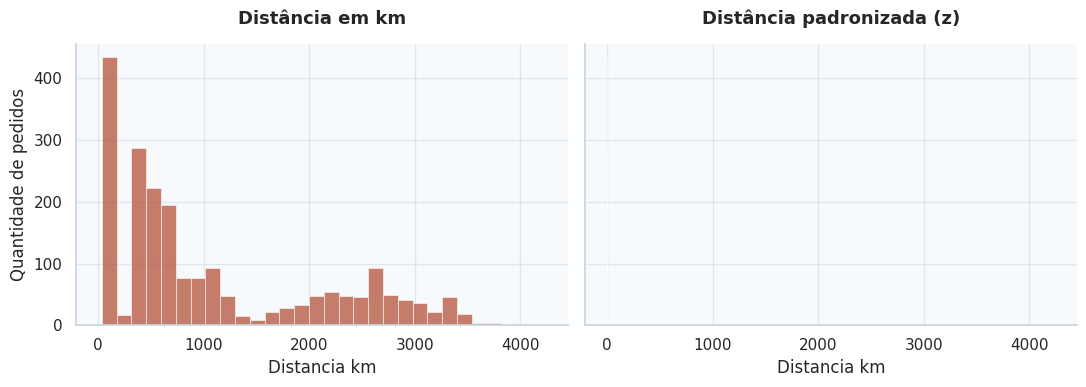

In [84]:
limpeza_escalonador.comparar_histogramas(treino[["distancia_km"]], pd.DataFrame({"distancia_km": z_treino}), "distancia_km", "Distância em km", "Distância padronizada (z)")

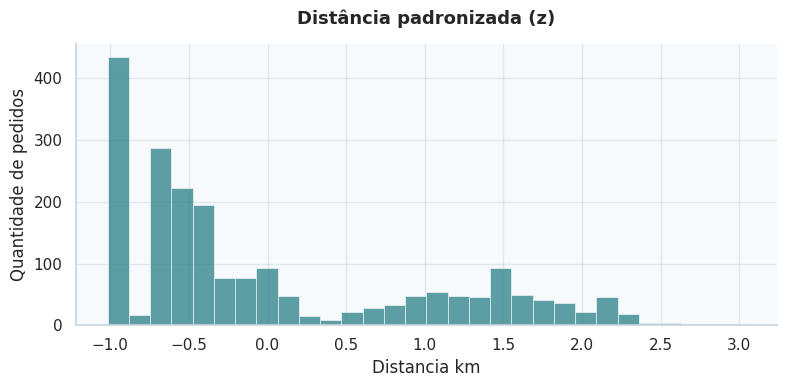

In [89]:
Visualizacao.histograma(pd.DataFrame({"distancia_km": z_treino}), "distancia_km", "Distância padronizada (z)")